# 04 — Compare the three forecasts

Use the matched sample and common error metrics; the previously inspected local test is a retrospective benchmark.

## Imports

In [1]:
from pathlib import Path
from types import SimpleNamespace
import os, json, time, warnings
import numpy as np
import pandas as pd
from IPython.display import display


In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/calendar.csv').exists())
DATA = ROOT / 'data'
OUT = DATA / 'processed'
RESULTS = ROOT / 'reports/results'
FIGURES = ROOT / 'reports/figures'
for folder in [OUT, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.venv/matplotlib'))


'/Users/moha/Machine-Learning-Project/Project 1/.venv/matplotlib'

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':100, 'axes.spines.top':False, 'axes.spines.right':False})
COLORS = ['#2563eb', '#059669', '#ea580c', '#7c3aed']


## Load prepared arrays

In [4]:
sales = np.load(OUT / 'sales.npy', mmap_mode='r')
prices = np.load(OUT / 'prices.npy', mmap_mode='r')
metadata = pd.read_csv(OUT / 'metadata.csv')
calendar = pd.read_csv(OUT / 'calendar.csv', parse_dates=['date'])
config = json.loads((ROOT / 'configs/comparison.json').read_text())
data = SimpleNamespace(root=ROOT)


In [5]:
def save_figure(data, name):
    plt.gcf().tight_layout()
    plt.gcf().savefig(FIGURES / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()


## Load the comparison results

In [6]:
scores=pd.read_csv(RESULTS / 'three_model_scores.csv')
sample=pd.read_csv(OUT / 'comparison_sample.csv')
diagnostics=pd.read_csv(RESULTS / 'three_model_fit_diagnostics.csv')
manifest=json.loads((RESULTS / 'three_model_manifest.json').read_text())
assert manifest['config']==config and manifest['sample_ids']==sample.series_id.tolist()
sample_rows=sample.row.to_numpy()
assert sample.series_id.tolist()==metadata.series_id.iloc[sample_rows].tolist()


## Comparable error metrics

In [7]:
def rmsse_scales(history):
    scales=[]
    for values in history:
        active=np.flatnonzero(values)
        differences=np.diff(values[active[0]:].astype('float64')) if len(active) else []
        scales.append(float(np.mean(np.square(differences))) if len(differences) else 0.)
    return np.asarray(scales)


In [8]:
def score_forecast(prediction, actual, scales):
    assert prediction.shape==actual.shape and np.isfinite(prediction).all()
    assert (prediction>=0).all() and (scales>0).all()
    error=prediction.astype('float64')-actual
    rmsse=np.sqrt(np.mean(error**2,axis=1)/scales)
    return dict(mae=float(np.abs(error).mean()), rmse=float(np.sqrt(np.mean(error**2))),
                mean_rmsse=float(rmsse.mean()))


## Recalculate every score from saved predictions

In [9]:
for result in scores.itertuples():
    prediction=np.load(DATA / f'interim/three_model_{result.model}_d{result.cutoff}.npy')
    actual=sales[sample_rows,result.cutoff:result.cutoff+28]
    scales=rmsse_scales(sales[sample_rows,:result.cutoff])
    recalculated=score_forecast(prediction,actual,scales)
    for metric,value in recalculated.items():
        assert np.isclose(value,getattr(result,metric))
print('All models use identical series, targets, horizons, and RMSSE scales.')


All models use identical series, targets, horizons, and RMSSE scales.


## Three-model comparison

In [10]:
development=scores[scores.phase=='development'].groupby('model').mean_rmsse.mean()
test=scores[scores.phase=='local_test'].set_index('model')
comparison=test[['mean_rmsse','mae','rmse']].rename(columns={
    'mean_rmsse':'test_rmsse','mae':'test_mae','rmse':'test_rmse'})
comparison.insert(0,'development_rmsse',development)
comparison=comparison.sort_values('development_rmsse')
comparison.to_csv(RESULTS / 'three_model_comparison.csv')
display(comparison)


,development_rmsse,test_rmsse,test_mae,test_rmse
model,,,,
SARIMA,0.721334,0.686533,0.950416,1.702237
ARIMA,0.722543,0.686761,0.951145,1.701184
LightGBM,0.727597,0.695901,0.939023,1.712525


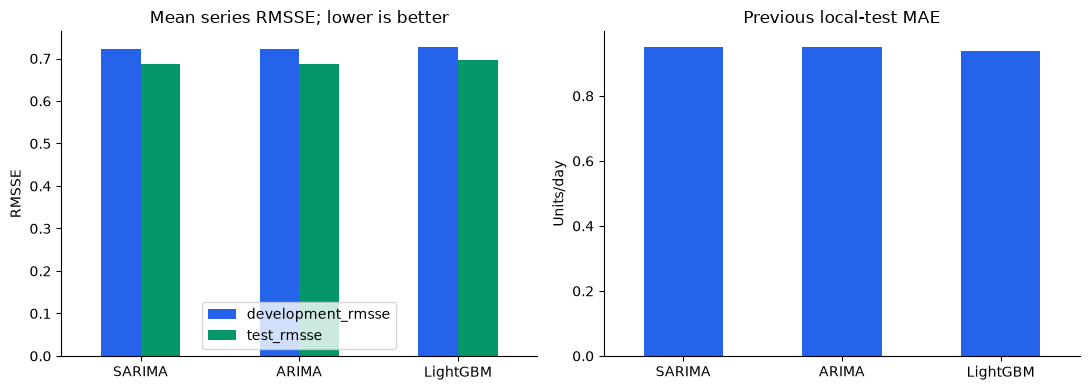

In [11]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
comparison[['development_rmsse','test_rmsse']].plot.bar(ax=axes[0],color=COLORS[:2])
axes[0].set(title='Mean series RMSSE; lower is better',xlabel='',ylabel='RMSSE')
comparison.test_mae.plot.bar(ax=axes[1],color=COLORS[0])
axes[1].set(title='Previous local-test MAE',xlabel='',ylabel='Units/day')
for ax in axes: ax.tick_params(axis='x',rotation=0)
save_figure(data,'comparison_01_three_models')


## Statistical fit diagnostics

In [12]:
convergence=diagnostics.groupby('model').agg(
    fits=('converged','size'),converged=('converged','sum'),
    warnings=('warnings','sum'),negative_raw_forecasts=('negative_raw_forecasts','sum'))
display(convergence)
print('Finite forecasts from nonconverged fits are retained and explicitly flagged.')
print('Negative statistical forecasts are clipped to zero for unit-sales prediction.')


,fits,converged,warnings,negative_raw_forecasts
model,,,,
ARIMA,270,270,0,0
SARIMA,270,270,0,1


Finite forecasts from nonconverged fits are retained and explicitly flagged.
Negative statistical forecasts are clipped to zero for unit-sales prediction.


## Error by forecast day

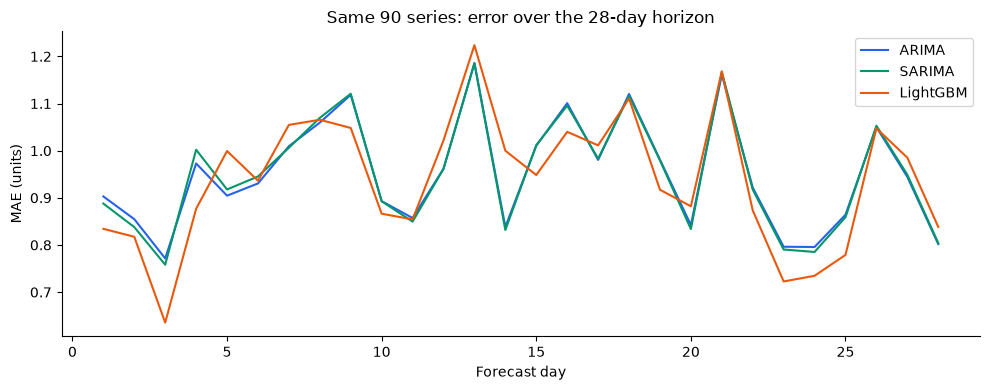

In [13]:
cutoff=config['test_cutoff']
actual=sales[sample_rows,cutoff:cutoff+28]
predictions={name:np.load(DATA / f'interim/three_model_{name}_d{cutoff}.npy')
             for name in ['ARIMA','SARIMA','LightGBM']}
horizon=pd.DataFrame({name:np.abs(values-actual).mean(axis=0)
                      for name,values in predictions.items()},index=np.arange(1,29))
horizon.plot(figsize=(10,4),color=COLORS[:3])
plt.xlabel('Forecast day'); plt.ylabel('MAE (units)')
plt.title('Same 90 series: error over the 28-day horizon')
save_figure(data,'comparison_02_horizon')


## Representative forecasts

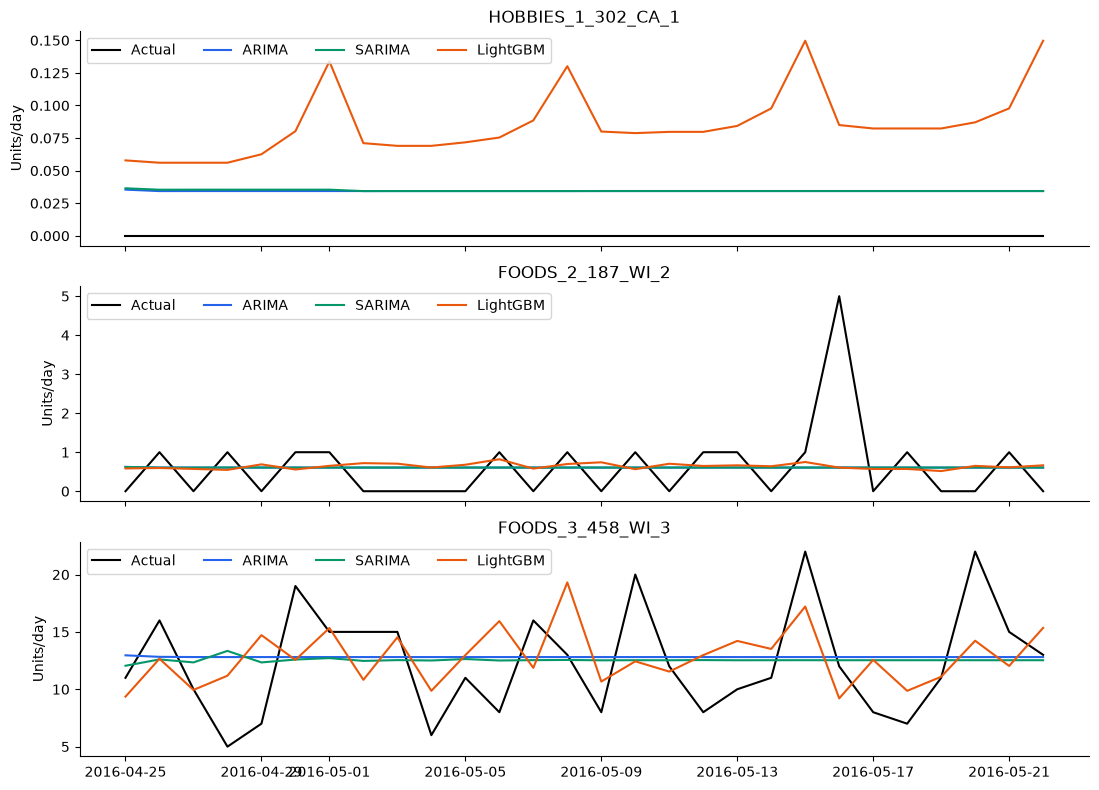

In [14]:
ordered=sample.mean_training_sales.sort_values().index
examples=[ordered[0],ordered[len(ordered)//2],ordered[-1]]
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True)
dates=calendar.date.iloc[cutoff:cutoff+28]
for ax,position in zip(axes,examples):
    ax.plot(dates,actual[position],color='black',label='Actual')
    for name,color in zip(['ARIMA','SARIMA','LightGBM'],COLORS):
        ax.plot(dates,predictions[name][position],label=name,color=color)
    ax.set(title=sample.series_id.iloc[position],ylabel='Units/day')
    ax.legend(ncol=4)
save_figure(data,'comparison_03_forecasts')


## Model summary for the README

In [15]:
model_summary="""## Model summary

| Model | Specification | Approach |
| --- | --- | --- |
| ARIMA | ARIMA(1,1,1) | Models each series without an explicit seasonal component. |
| SARIMA | SARIMA(1,1,1)(1,0,0,7) | Adds a weekly seasonal component to each series. |
| LightGBM | 200 trees, 31 leaves, learning rate 0.05 | Uses calendar and lag features to correct a recent weekday-average forecast. |

ARIMA and SARIMA fit each series separately; LightGBM learns across related series.
"""


## Evaluation table for the README

In [16]:
readable=comparison.rename(columns={
    'development_rmsse':'Development RMSSE', 'test_rmsse':'Local-test RMSSE',
    'test_mae':'Local-test MAE', 'test_rmse':'Local-test RMSE'})
header='| Model | '+' | '.join(readable.columns)+' |'
separator='| '+' | '.join(['---']*(len(readable.columns)+1))+' |'
rows=['| '+name+' | '+' | '.join(f'{x:.4f}' for x in row)+' |'
      for name,row in readable.iterrows()]
evaluation_table='\n'.join([header,separator,*rows])


In [17]:
start_date=calendar.date.iloc[config['test_cutoff']].strftime('%Y-%m-%d')
end_date=calendar.date.iloc[config['test_cutoff']+27].strftime('%Y-%m-%d')
fit_count=int(convergence.fits.sum())
converged_count=int(convergence.converged.sum())
evaluation_intro=f"""## Evaluation

The three models forecast the same **{len(sample)} product/store series** for **28 days**,
balanced across stores, categories, and training-volume bands. Two development
windows precede the local test, **{start_date} to {end_date}**. The local test was
previously inspected, so this is a retrospective comparison. RMSSE is averaged
equally across the sampled series. All {converged_count}/{fit_count} statistical fits converged.
"""


## Comparison graphs for the README

In [18]:
graphs="""## Comparison graphs

### Model scores

![ARIMA, SARIMA, and LightGBM scores](reports/figures/comparison_01_three_models.png)

### Error across the forecast horizon

![MAE by forecast day](reports/figures/comparison_02_horizon.png)
"""


In [19]:
forecast_graph="""### Representative forecasts

Examples from low-, medium-, and high-volume series selected using training data.

![Actual sales and three-model forecasts](reports/figures/comparison_03_forecasts.png)
"""


## Final comparison in the README

In [20]:
rmsse_winner=comparison.test_rmsse.idxmin()
mae_winner=comparison.test_mae.idxmin()
rmse_winner=comparison.test_rmse.idxmin()
conclusion=f"""## Final comparison

**{rmsse_winner}** has the lowest mean RMSSE, **{mae_winner}** the lowest MAE,
and **{rmse_winner}** the lowest RMSE. The differences are small, particularly
between ARIMA and SARIMA. These results describe this matched sample with
fixed model settings.
"""


In [21]:
intro="""# Retail Sales Forecasting: ARIMA, SARIMA, and LightGBM

A retail time series study using M5 sales data to compare statistical forecasting
with machine learning over a 28-day horizon.
"""
readme='\n\n'.join(section.strip() for section in [
    intro,model_summary,evaluation_intro,evaluation_table,graphs,forecast_graph,conclusion])+'\n'
(ROOT / 'README.md').write_text(readme)
print('Updated README.md with model summaries, evaluation, and comparison graphs.')


Updated README.md with model summaries, evaluation, and comparison graphs.
